# 4.1. NumPy - numerical Python

Module M-227-04: Programming for Data Analytics

Instructor: Nadežda Zeņina

Course author: Dmitry Pavlyuk

## Previous lesson review

Warm-up: *Check yourself 4.1 - weeks 1-3 recap*


## Today

1. **Multidimensional data** - why a list is not enough
2. **NumPy arrays** - `ndarray`, shape, dtype, speed
3. **Creating arrays** - zeros, ones, ranges, random numbers, from a CSV file
4. **Indexing, slicing, masks** - picking the data you need
5. **View vs. copy** - the most common NumPy surprise
6. **Element-wise and matrix operations**, universal functions
7. **Statistics along an axis** and **broadcasting**
8. **Saving / restoring** arrays

## Multidimensional Data

* Geospatial data sets
    * Longitude/latitute (2 dimensions)
    * Time (1 dimension)
    * Indicators - temperature, humidity, pressure, etc. (1 dimension)
    * Weather forecasting, transport modelling, air pollution monitoring, GPS navigation
* Images
    * Coordinates (2 dimensions)
    * Channels (1 dimensional)
      * Object detection, facial recognition, medical image analysis, computer vision.
* Video (Images + Time)
    * Traffic monitoring, vehicle tracking, surveillance systems, action recognition.
* OLAP cubes (hypercubes) - multidimensional
    * Business intelligence, sales analysis, financial reporting, customer behaviour analysis.
* Tensors in machine learning - multidimensional
    * Neural networks, deep learning, image classification, natural language processing (NLP).

 NumPy gives us one object - the **array** - that stores all these shapes and does the arithmetic for us.

A NumPy array has a shape - one number per dimension - and every element has the same type
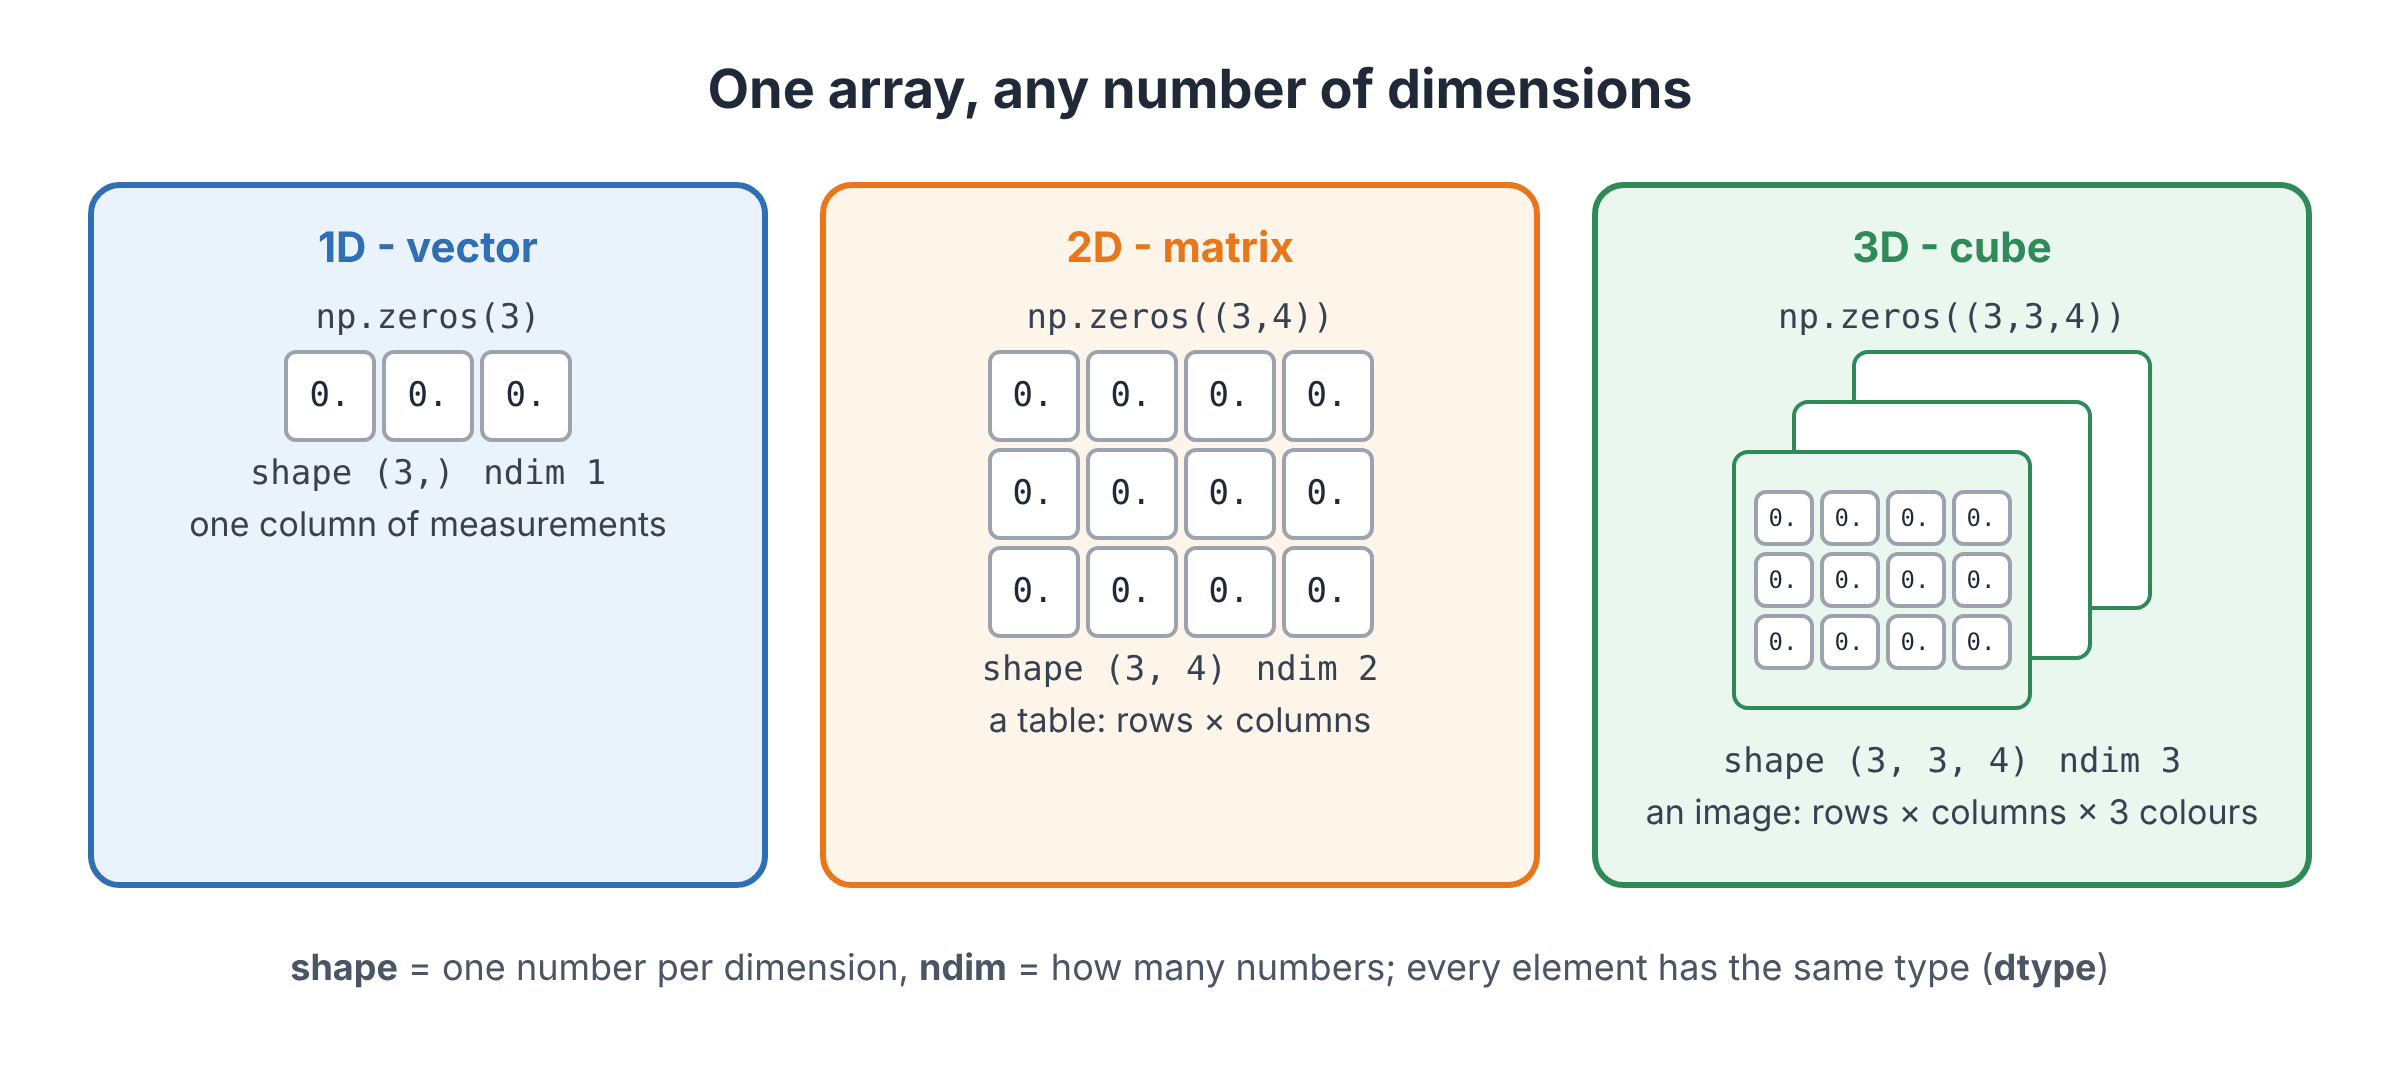

## NumPy

NumPy is a library that adding support for large multi-dimensional arrays, along with a large collection of high-level mathematical functions to operate on these arrays

NumPy is a **third-party library**: it is not part of Python itself, so it has to be installed once with `pip`. In Google Colab it is already installed - the cell below only confirms that.

In [ ]:
!pip install numpy

The usual way to import it is with the short name `np` - you will see `np.`

In [ ]:
import numpy as np
print(np.__version__)

* Efficient multidimensional array (ndarray) providing fast array-oriented arithmetic operations and flexible broadcasting capabilities
* Mathematical functions (linear algebra, statistics) for fast operations on entire arrays of data without having to write loops
* Tools for reading/writing array data to disk and working with memory-mapped files

A list is a row of separate boxes of any type; an array is one block of equal cells - that is why it is fast
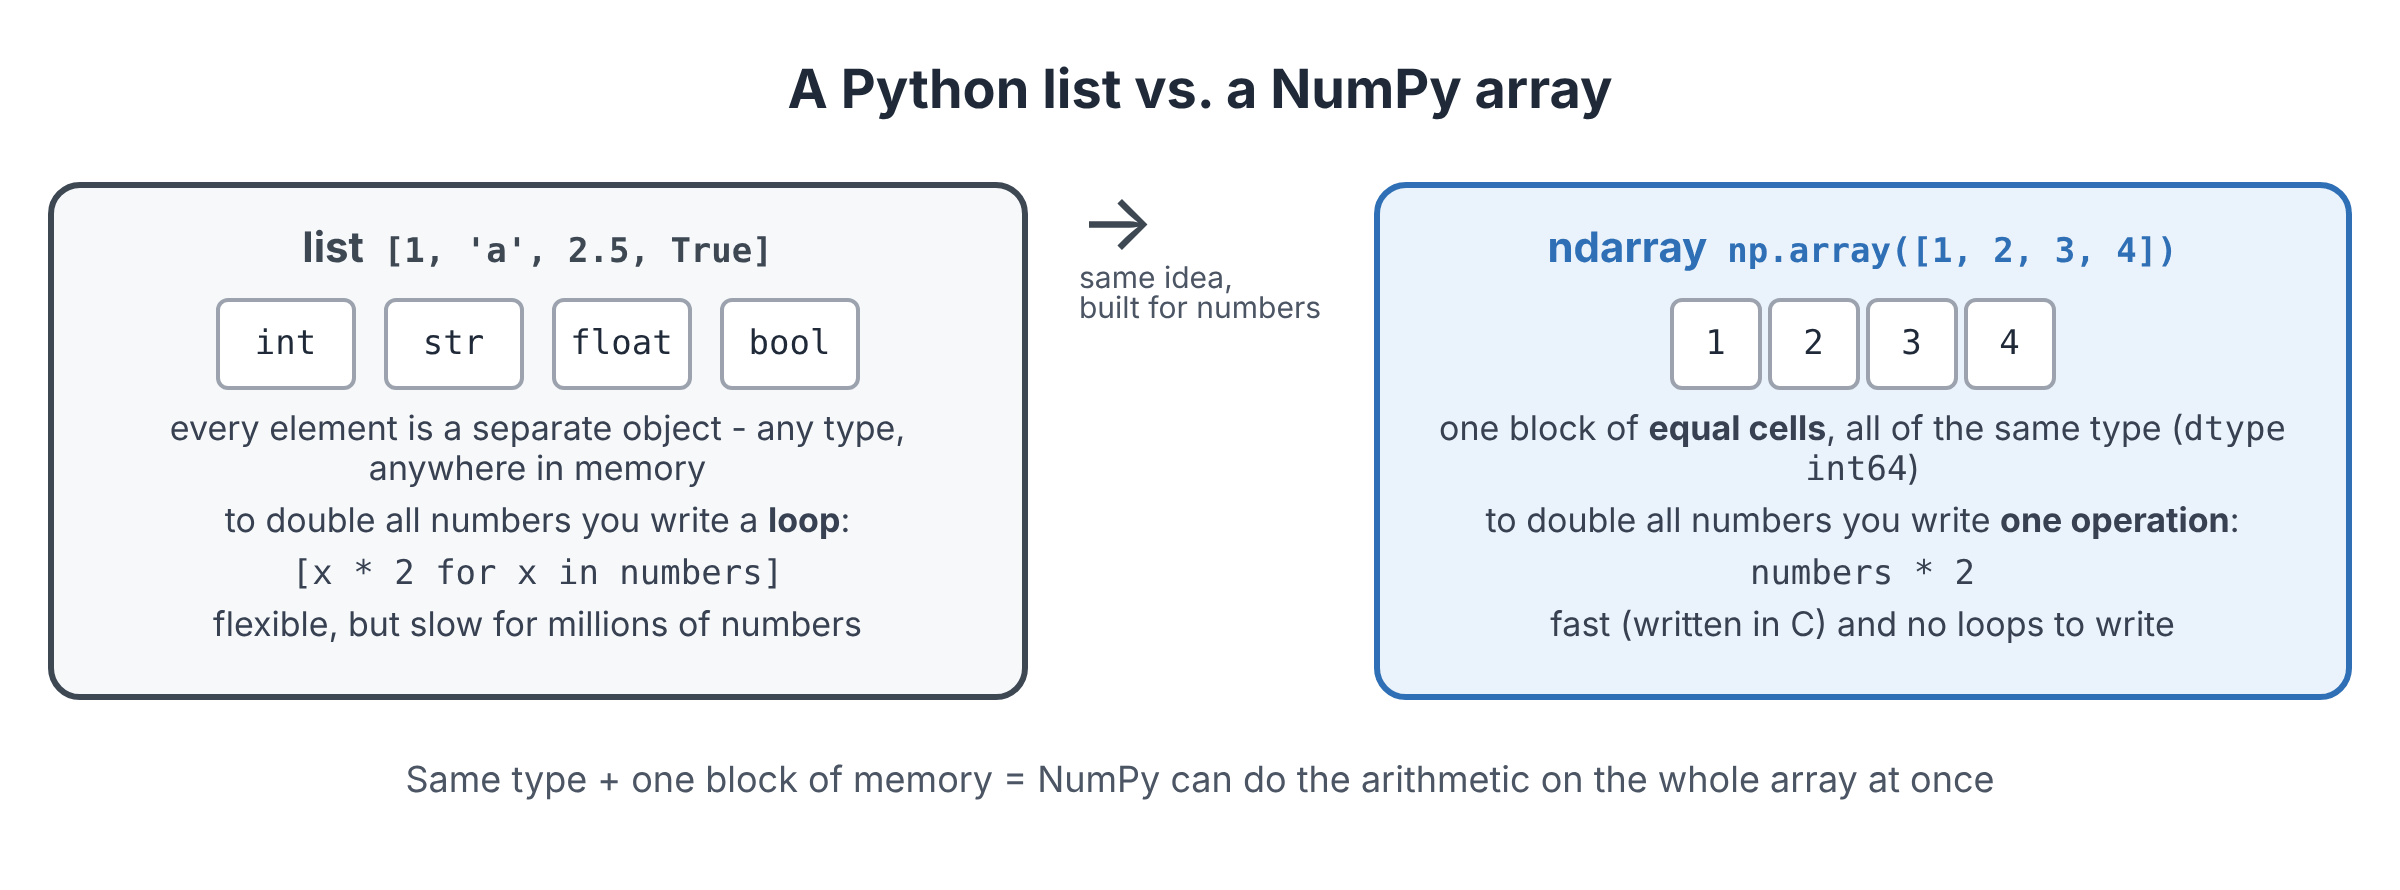

### One-dimensional arrays - vectors

`np.zeros(n)` creates an array of `n` zeros. Note the output: `array([...])` - NumPy prints its own type, not a list. The dot after every `0.` tells us the numbers are **floats**.

In [ ]:
arr1d = np.zeros(3)
arr1d

### Two-dimensional arrays - matrices

For two dimensions we pass the shape as a **tuple** `(rows, columns)` - note the double brackets `((3,3))`: the outer pair calls the function, the inner pair is the tuple.

In [ ]:
arr2d = np.zeros((3,3))
arr2d

### Three-dimensional arrays - cubes

Three numbers in the shape - three dimensions. Think of it as 3 tables, each with 3 rows and 4 columns (or: 3 "layers" of a cube).

In [ ]:
arr3d = np.zeros((3,3,4))
arr3d

### Asking an array about itself

Every array knows its **shape** (a tuple), its number of dimensions **ndim**, its number of elements **size** and its **dtype** (the type of the elements). You will use `.shape` more often than anything else in NumPy.

In [ ]:
for arr in (arr1d, arr2d, arr3d):
    print(f"shape: {arr.shape},  ndim: {arr.ndim},  size: {arr.size},  dtype: {arr.dtype}")

## Efficiency of operations

`timeit` runs a piece of code many times and reports the total time. Let us compare creating one million numbers with NumPy and with a plain Python list (100 repetitions each).

In [ ]:
import timeit

In [ ]:
timeit.timeit("np.arange(1000000)", number=100, setup="import numpy as np")

In [ ]:
timeit.timeit("list(range(1000000))", number=100)

NumPy is typically **10-50 times faster** - and the difference grows when we start computing. The reason is the picture above: NumPy stores the numbers in one block of memory and does the arithmetic in compiled C code, instead of Python visiting every element one by one.

The same comparison for a calculation - squaring a million numbers:

In [ ]:
numbers = list(range(1000000))
arr = np.arange(1000000)

print("list + loop:", timeit.timeit(lambda: [x * x for x in numbers], number=10))
print("NumPy      :", timeit.timeit(lambda: arr * arr, number=10))

Notice **what we wrote**, not only how fast it ran: `arr * arr` - no loop at all. This is called **vectorisation**: an operation on an array applies to every element. From now on, when you catch yourself writing `for` over numbers, ask "is there a NumPy way?"

### YOUR TURN 1: first arrays

1. Create a 2D array of zeros with 2 rows and 5 columns; print it and its `shape`.
2. Create a 3D array of zeros with shape `(2, 3, 4)`. How many elements does it have? Check with `.size`.
3. Create a 1D array `np.arange(10)` and print it multiplied by 10 - without a loop.
4. What is the `ndim` of `np.zeros((4,))`? And of `np.zeros((4, 1))`? Check your guess.

In [ ]:
# YOUR CODE HERE:

In [ ]:
# 1.
z = np.zeros((2, 5))
print(z)
print(z.shape)

# 2.
cube = np.zeros((2, 3, 4))
print(cube.size)          # 2 * 3 * 4 = 24

# 3.
print(np.arange(10) * 10)

# 4.
print(np.zeros((4,)).ndim, np.zeros((4, 1)).ndim)     # 1 and 2 - a column with one column is still 2D

## ndarray - internal structure

__ndarray__ internally consists of the following:

* Pointer to data - a block of data in RAM or in a memory-mapped file
* Data type or dtype describing fixed-size value cells in the array
* Tuple indicating the array's shape
* Tuple of strides - integers indicating the number of bytes to step in order to advance one element along a dimension

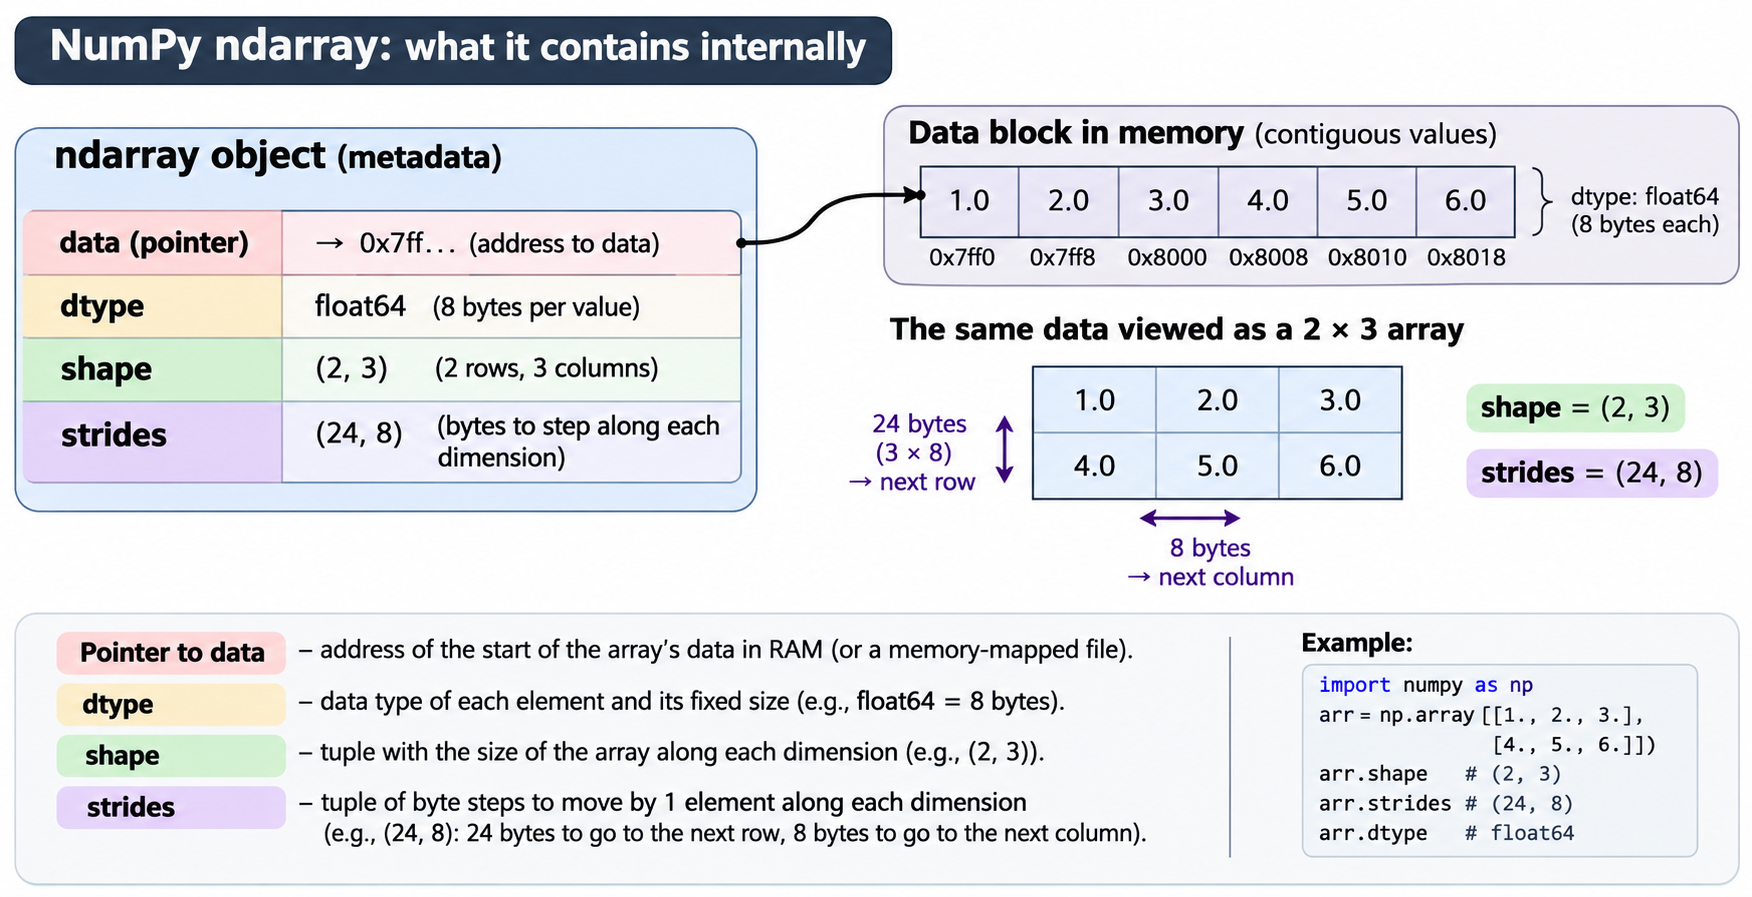

An array is **one block of memory** + a description of how to read it. In this course you need **shape** and **dtype**; *strides* are shown here only to explain *why* NumPy is fast - it never copies the data, it just changes the description (that is what `reshape`, `.T` and slicing do).

In [ ]:
arr = np.ones((2,3))
print(arr)
print(arr.shape)
print(arr.dtype)
print(arr.strides)

### Data types - int, short, uint, ushort

By default NumPy stores **floats** (`float64` - 8 bytes per number). With `dtype=` we can ask for integers, which take less memory: compare the `strides` (bytes per step) in the three cells.

In [ ]:
arr = np.ones((2,3), dtype=int)
print(arr)
print(arr.shape)
print(arr.dtype)
print(arr.strides)

In [ ]:
arr = np.ones((2,3), dtype=np.short)
print(arr)
print(arr.shape)
print(arr.dtype)
print(arr.strides)

### Data types - hierarchy

<img src="https://numpy.org/doc/stable/_images/dtype-hierarchy.png" alt="NumPy data types">

The ones you will meet: `int64` (whole numbers), `float64` (decimals), `bool` (True / False), `uint8` (0...255 - images, lesson 4.2) and `<U...` (text). Remember: **one array = one dtype**; NumPy picks the "widest" type that fits everything you give it:

In [ ]:
print(np.array([1, 2, 3]).dtype)           # all whole numbers -> int
print(np.array([1, 2.5, 3]).dtype)         # one decimal -> everything becomes float
print(np.array([1, "two", 3]).dtype)       # one string -> EVERYTHING becomes text  (a common trap with CSV files!)
print(np.array([True, False]).dtype)

### Converting data type

`astype()` returns a **new array** with another dtype. Two situations where you will need it:

* integers → floats, because a missing value `np.nan` ("not a number") can only live in a **float** array
* text → numbers after reading a file where everything came as strings

In [ ]:
arr.astype(float)

## Creating arrays

### Standard arrays:
* np.ones - array of ones
* np.zeros - array of zeros
* np.eye, np.identity - identity matrix (ones on the diagonal, zeros elsewhere)

### Examples

In [ ]:
np.ones((2,3,2))

In [ ]:
np.zeros((2,3,2))

In [ ]:
np.eye(3)

### From list or tuple:

`np.array()` converts any list (or list of lists) into an array - this is how you turn data you already have into NumPy.

In [ ]:
np.array([1, 2, 3, 4, 5])

In [ ]:
np.array([[1, 2, 3],
          [4, 5, 6]])            # a list of lists -> a 2D array (every inner list = one row)

### From iterable:

Anything you could loop over (`range`, a generator) works too. `np.arange` is NumPy's own `range` - it builds the array directly and also accepts decimal steps.

In [ ]:
np.array(range(5))

In [ ]:
np.array(np.arange(5))

In [ ]:
print(np.arange(5))                 # 0 .. 4
print(np.arange(2, 11, 2))          # start, stop (not included), step - as range()
print(np.arange(0, 1, 0.25))        # decimal steps are allowed (range() cannot do this)

In [ ]:
arr = np.array(np.arange(12))
arr.reshape(3,4)

### From CSV

The **iris** data set: 150 flowers, 4 measurements each (sepal length and width, petal length and width, in cm) and the species name. It is the "hello world" of data analytics. First we make sure the file is in our working folder (in Colab we download it from the course repository):

In [ ]:
iris_data = np.genfromtxt('iris.csv', delimiter=',', skip_header=1, usecols=(0,1,2,3))
iris_data[0:10]

`np.genfromtxt` reads a text table straight into an array. The arguments mirror what we did by hand in 3.2: `delimiter=','` (the column separator), `skip_header=1` (skip the header line), `usecols=(0,1,2,3)` (only the numeric columns - remember, one array = one dtype, so the text column `variety` must stay out).

In [ ]:
iris_data = np.genfromtxt('iris.csv', delimiter=',', skip_header=1, usecols=(0,1,2,3))
iris_data[0:10]

In [ ]:
print(iris_data.shape)
print(iris_data.dtype)

### YOUR TURN 2: creating arrays

1. Create the numbers from 1 to 24 with `np.arange` and reshape them into 4 rows and 6 columns.
2. Put the first 12 prime numbers `2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37` into an array and reshape it into 3 rows × 4 columns.
4. How many rows does `iris_data` have? Print the **last** 3 rows.

In [ ]:
# YOUR CODE HERE:

In [ ]:
# 1.
print(np.arange(1, 25).reshape(4, 6))

# 2.
primes = np.array([2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37])
print(primes.reshape(3, 4))

# 3.
print(iris_data.shape[0])
print(iris_data[-3:])

## Basic operations

### Reshaping

The same 12 numbers can be arranged as 2×6, 6×2 or 3×4 - `reshape` only changes the *description*, the data stays in the same order (row by row). The product of the new shape must equal the number of elements.

In [ ]:
arr = np.array(np.arange(1,13))
arr

In [ ]:
print(arr.reshape(2,6))

In [ ]:
print(arr.reshape(6,2))

In [ ]:
print(arr.reshape(3,4))

How to reshape to get...

```
[[[ 1  2]
  [ 3  4]
  [ 5  6]]

 [[ 7  8]
  [ 9 10]
  [11 12]]]
```



In [ ]:
print(arr.reshape(2,3,2))

In [ ]:
print(arr.reshape(2,-1))        #NumPy infers that size automatically.

In [ ]:
arr.reshape(5, 3)                 # 5 * 3 = 15 != 12 -> error

### Indexing

For a list we wrote `x[i]`. For a 2D array we write `arr[row, column]` - one position per dimension, separated by a comma. Counting starts from 0, as always.

[row, column] - one position per dimension; ':' means 'all', start:stop stops before stop - exactly as for lists
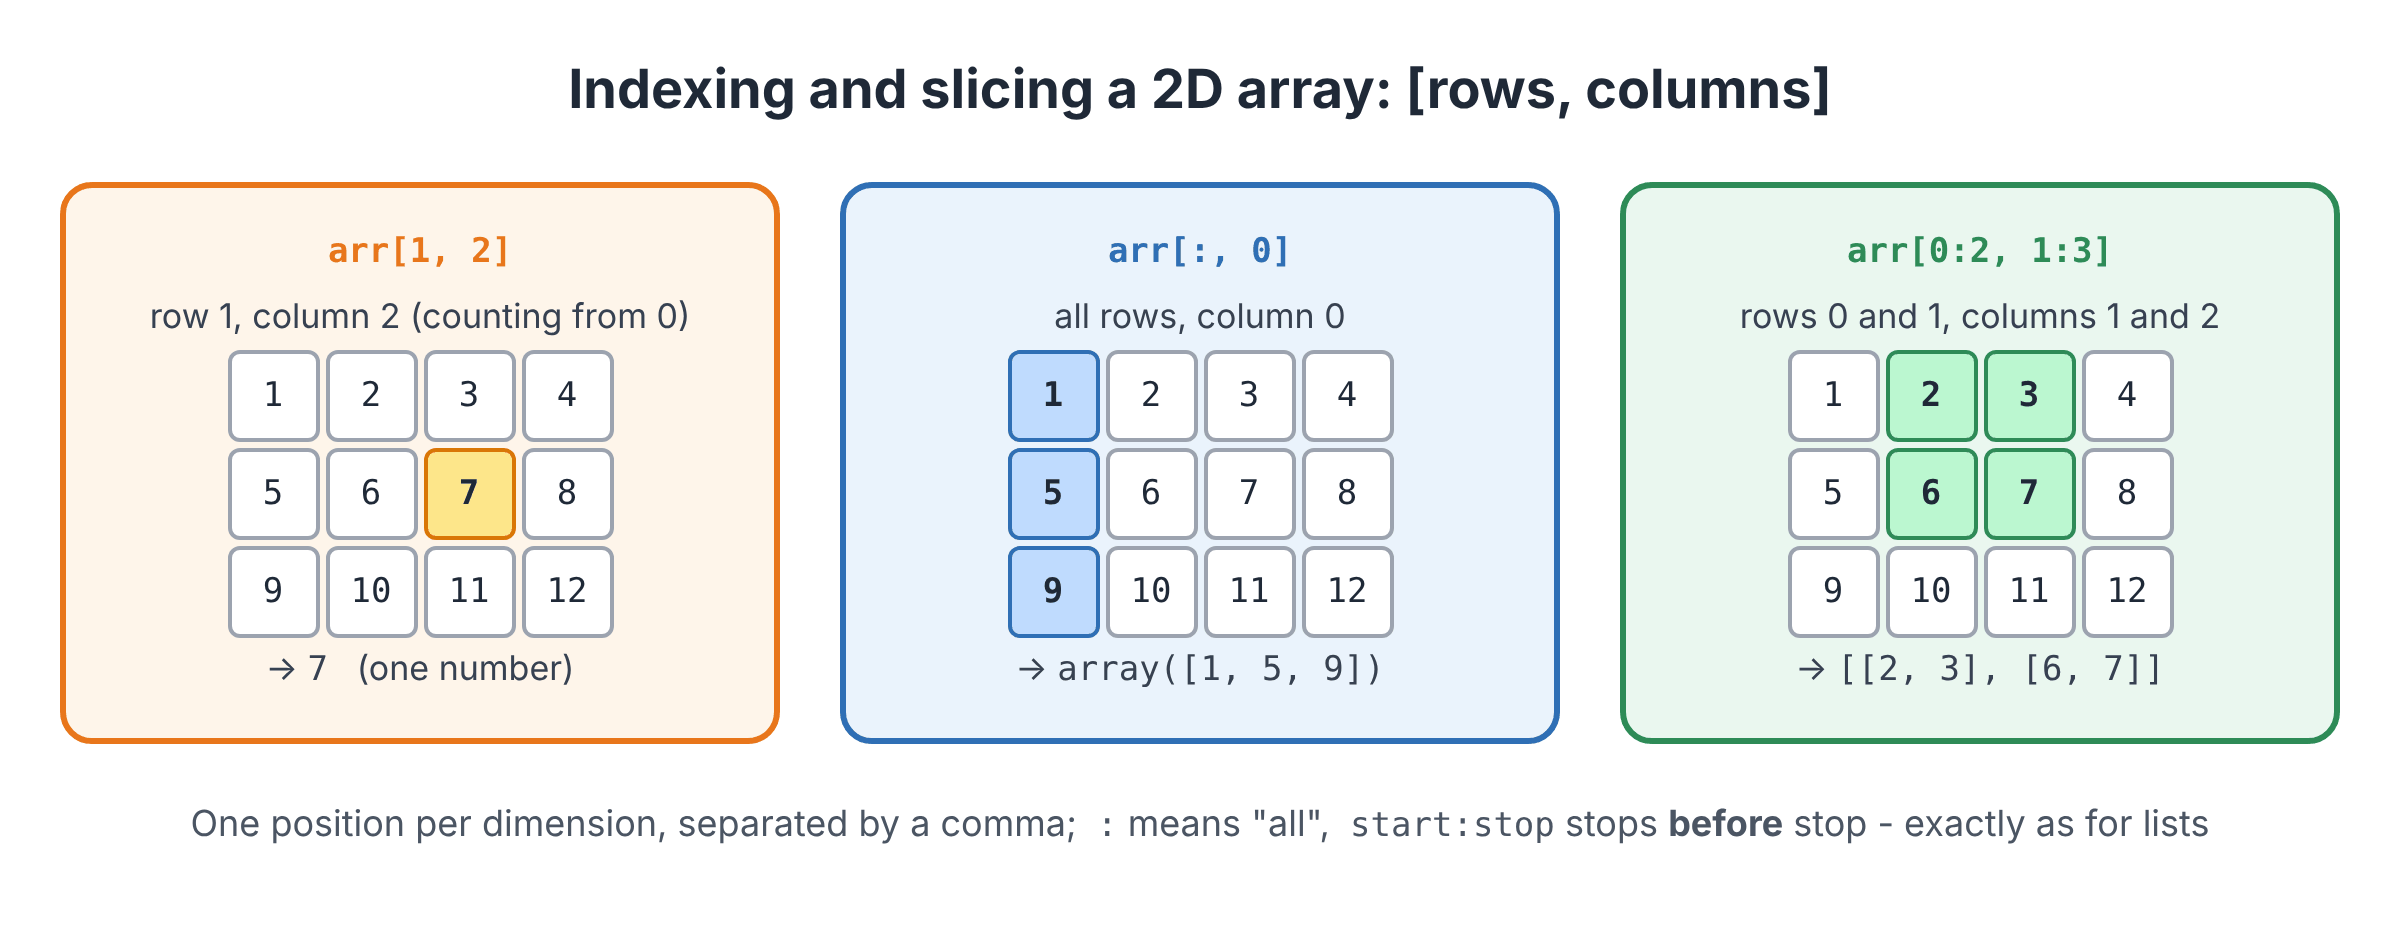

In [ ]:
arr = arr.reshape(3,4)
arr

* First element:

In [ ]:
arr[0,0]

* First column:

In [ ]:
arr[:,0]

* More examples - a whole row, the last element, a single value:

In [ ]:
print(arr[0])          # first row (one index -> the whole row)
print(arr[-1])         # last row
print(arr[1, 2])       # row 1, column 2
print(arr[-1, -1])     # the very last element

### Fancy indexing

Fancy indexing allows indexing an array using a sequence of integers

In [ ]:
print("Full array:\n",arr)
print("Indexing:\n",arr[[2,0,1]])

Instead of one index we pass a **list of indices** - we get those rows, in the order we asked. Useful for re-ordering (here: row 2, then 0, then 1) and for picking several specific columns:

In [ ]:
print(arr[:, [0, 3]])        # columns 0 and 3 only
print(iris_data[[0, 50, 100]])   # one flower of each species (rows 0, 50, 100)

### Boolean indexing

The most important idea of today for data analytics: **filtering with a condition**. A comparison applied to an array gives an array of `True` / `False` of the same shape (a **mask**); indexing with the mask keeps only the elements where it is `True`.

Comparison → True/False array; the mask keeps the rows where it is True
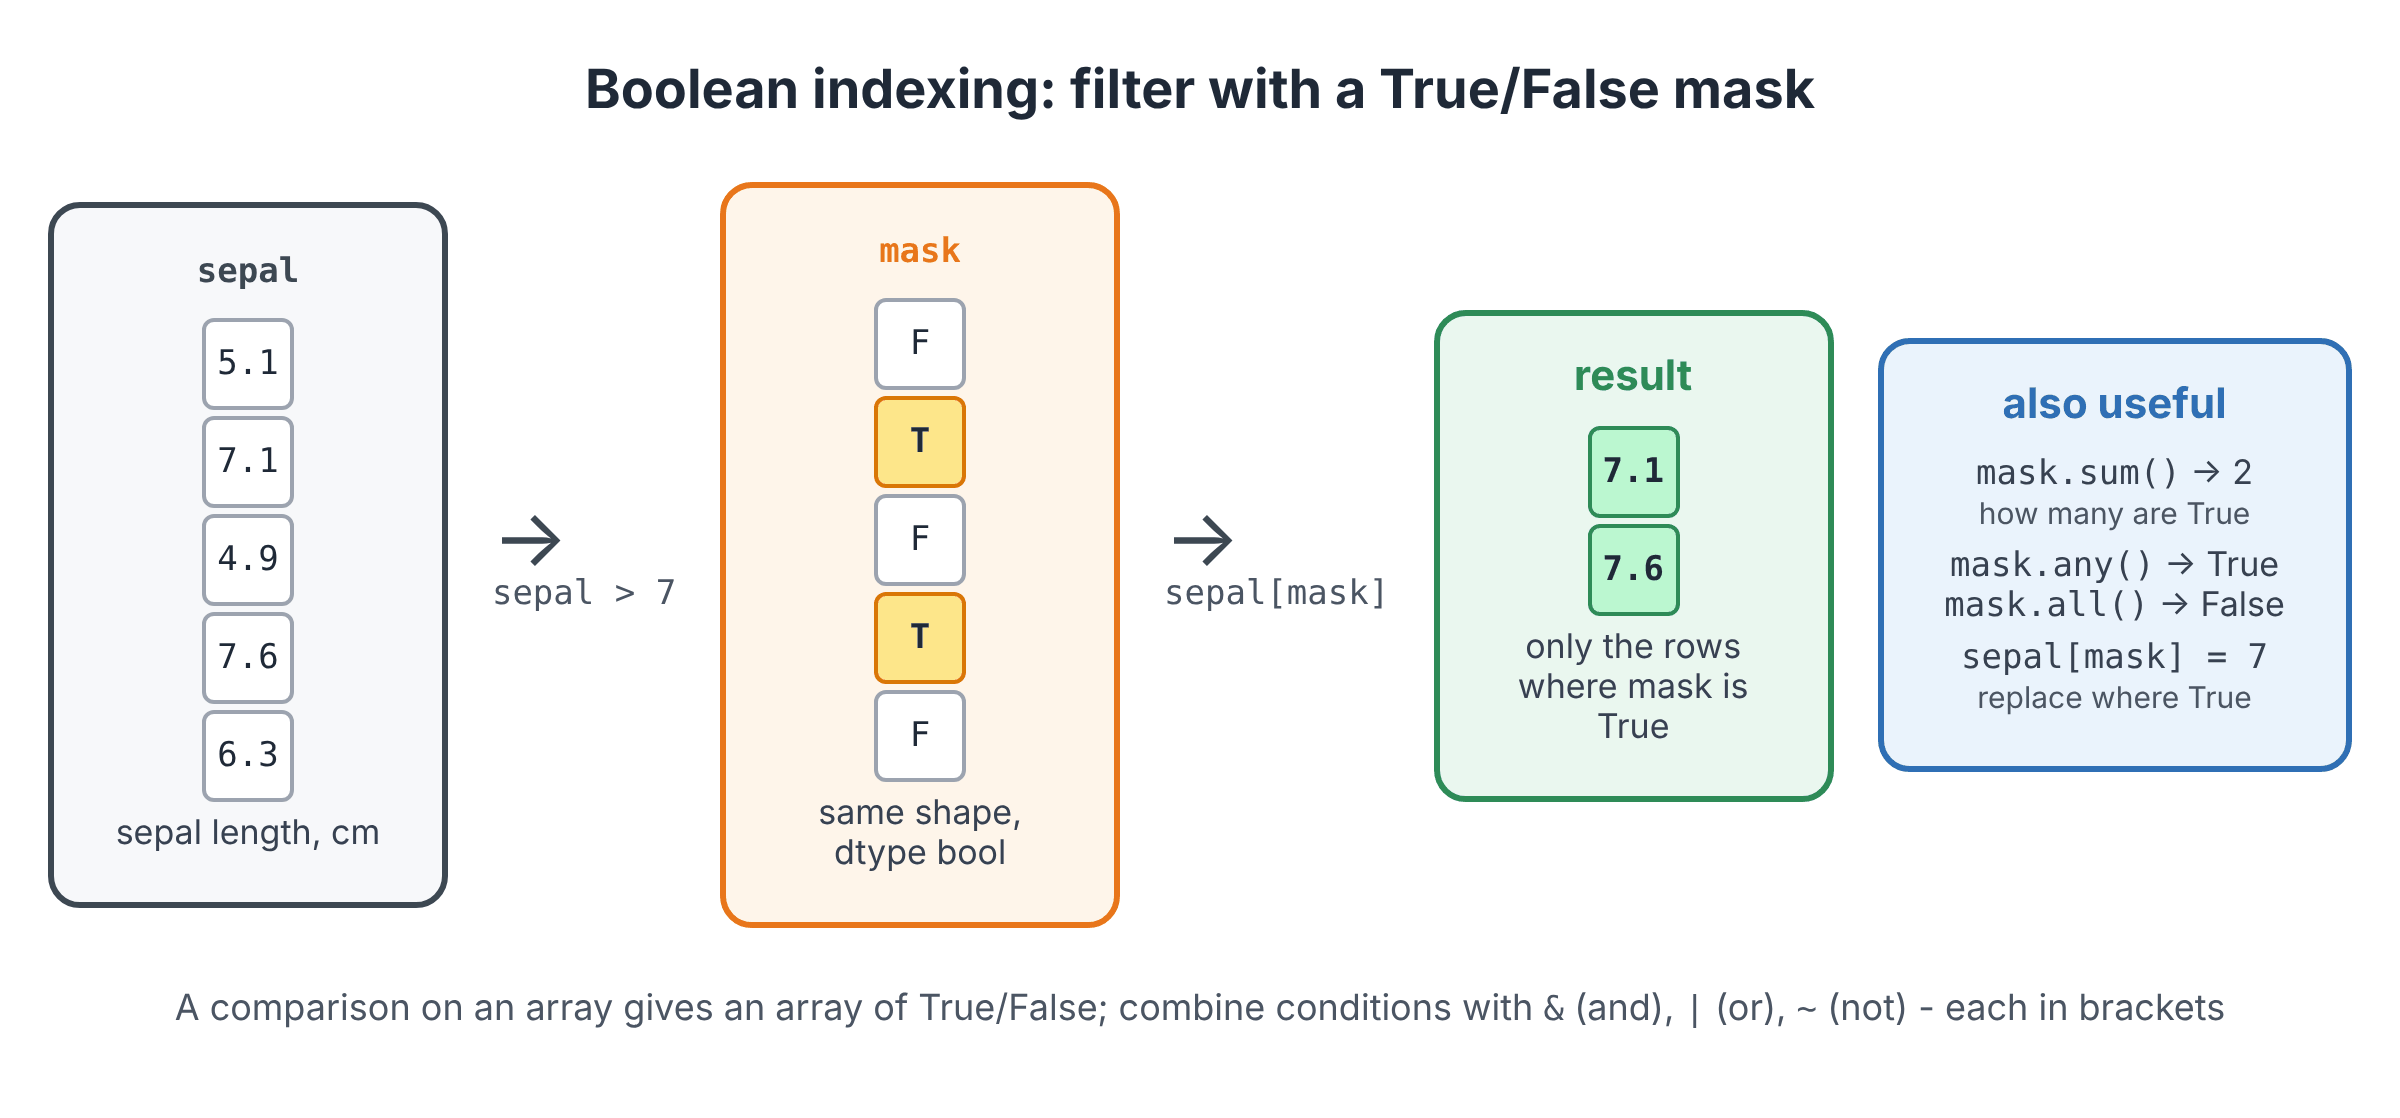

In [ ]:
print(arr)
arr[[True,False,True]]

In [ ]:
large = iris_data[:,0]>7
large
#np.sum(large)

In [ ]:
iris_data[large]

What the three lines above mean: `iris_data[:, 0]` is the column of sepal lengths (150 values); `> 7` turns it into 150 booleans; `iris_data[large]` keeps the **rows** where the boolean is `True` - the flowers with sepal length over 7 cm. Usually it is written in one line:

### Slicing

For every dimension the slice object is __[start:end:step]__
* If we don't pass start its considered 0
* If we don't pass end its considered length of array in that dimension
* If we don't pass step its considered 1

* First column:

In [ ]:
print(arr)
arr[:,0:1] #select all rows and only the first column.

(Compare with `arr[:, 0]` above: the slice `0:1` keeps the dimension - a 3×1 column - while the index `0` drops it - a 1D array of 3.)

* First 2 columns:

In [ ]:
arr[:,0:2]

* First row:

In [ ]:
arr[0:1,:]

* First 2 rows:

In [ ]:
arr[0:2,:]

* First 2 rows of iris data set:

In [ ]:
iris_data[0:2,:]

### YOUR TURN 3: indexing and slicing the iris data

Columns: `0` sepal length, `1` sepal width, `2` petal length, `3` petal width (cm).

1. Print the petal length column (all 150 values). Print only its first 5 values.
2. Print rows 10 to 19 (ten flowers), columns 0 and 1 only.
3. How many flowers have a petal length greater than 5 cm?


In [ ]:
# YOUR CODE HERE:

In [ ]:
# 1.
print(iris_data[:, 2])
print(iris_data[:5, 2])

# 2.
print(iris_data[10:20, 0:2])

# 3.
print((iris_data[:, 2] > 5).sum())


## Slicing Vs. Copy

In week 2 we saw that `b = a` for lists does not copy the list. NumPy goes one step further: even a **slice** is not a copy - it is a *view*, a window onto the same data. Changing the view changes the original.

A slice is a window onto the same data; .copy() makes a new block
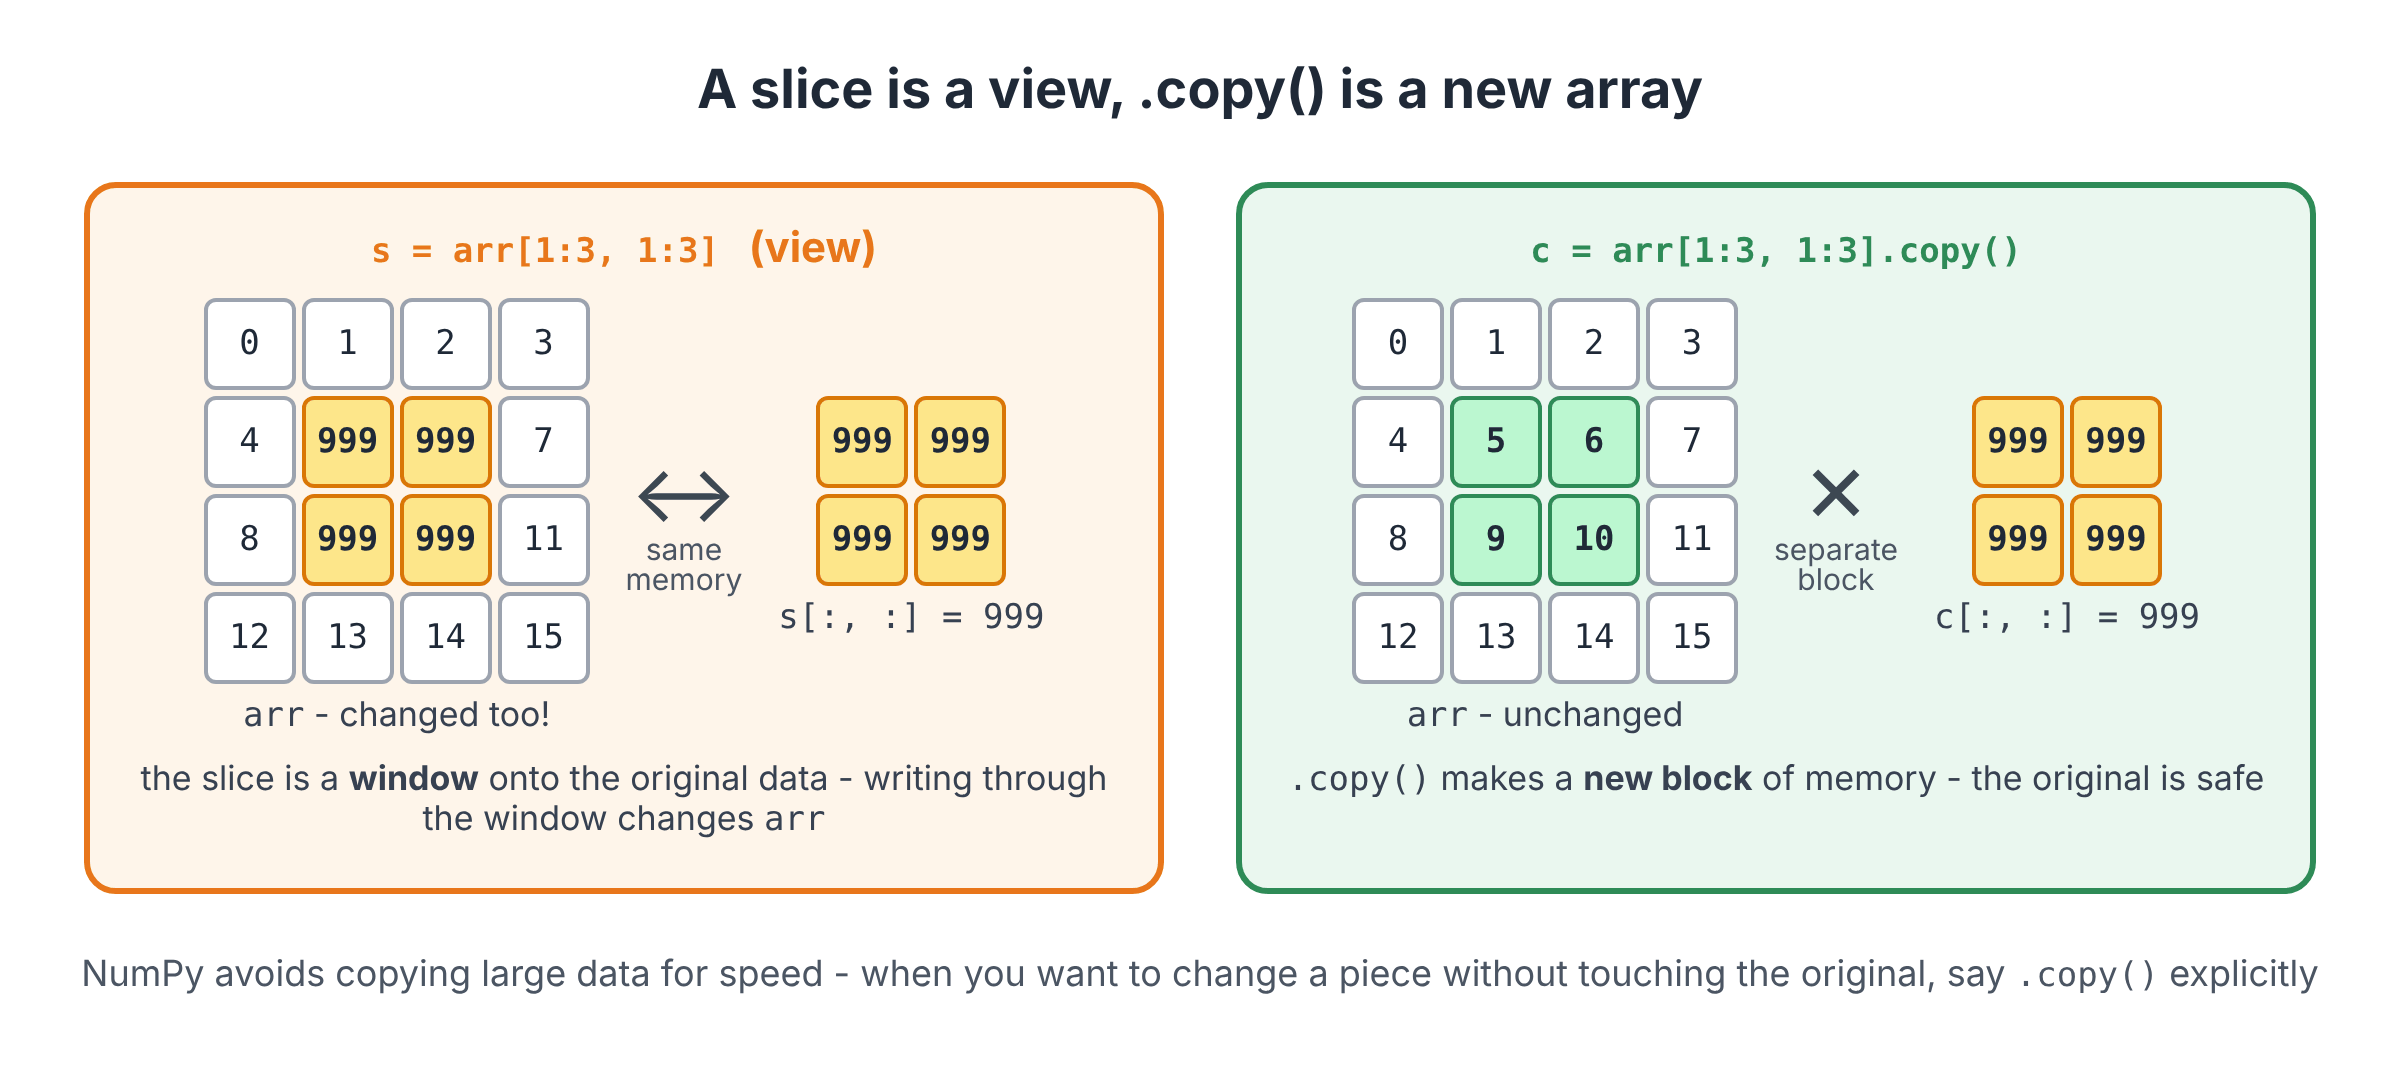

### Slicing / View

In [ ]:
arr = np.arange(16).reshape(4,4)
print("Full array:\n",arr)

arr_slice = arr[1:3, 1:3]
print("Slice:\n", arr_slice)

In [ ]:
arr_slice[:,:]=999
print("Slice:\n", arr_slice)
print("Full array:\n",arr)

### Copying

When you want to change a piece without touching the original, say `.copy()` explicitly:

In [ ]:
arr = np.arange(16).reshape(4,4)
arr_slice_copy = arr[1:3, 1:3].copy()
arr_slice_copy[:,:]=999
print("Slice:\n", arr_slice_copy)
print("Full array:\n",arr)

Rule of thumb: slicing → view (fast, shares memory); **boolean indexing and fancy indexing → copy** (a new array). When in doubt, `.copy()` is never wrong - only a bit slower.

## Element-wise Operations

Arithmetic between two arrays of the **same shape** works element by element: the first with the first, the second with the second... No loop.

In [ ]:
np.random.seed(0)
arr1 = np.random.randint(1,10,(3,3))
print(f"Array 1:\n {arr1}")

arr2 = np.random.randint(1,10,(3,3))
print(f"Array 2:\n {arr2}")

* Sum/Difference

In [ ]:
arr1+arr2

In [ ]:
arr1-arr2

* Join

`np.concatenate` glues arrays together: along `axis=0` (default) rows are stacked **under** each other, along `axis=1` **next to** each other. We will use it in 4.2 to show several images side by side.

In [ ]:
np.concatenate((arr1, arr2))

In [ ]:
np.concatenate((arr1, arr2), axis=1)

* Element-wise (Hadamard) Multiplication

In [ ]:
print(np.multiply(arr1, arr2))

In [ ]:
print(arr1 * arr2)          # the same with the operator
print(arr1 / arr2)          # division - the result is float
print(arr1 ** 2)            # power


### Universal functions

Fast Element-Wise Array Functions
* np.sqrt
* np.exp
* np.isnan
* np.where

In [ ]:
print(f"Array:\n {arr1}")
print(f"Element-wise square root:\n {np.sqrt(arr1)}")

A *universal function* (ufunc) takes an array and returns an array of the same shape, applying the function to every element. `math.sqrt` from week 3 works on **one** number; `np.sqrt` on a million at once.

In [ ]:
print(np.exp(np.array([0, 1, 2])))            # e^x
print(np.round(np.sqrt(arr1), 2))             # round to 2 decimals
print(np.abs(arr1 - arr2))                    # absolute value of the difference

with_gaps = np.array([1.5, np.nan, 3.0, np.nan])
print(np.isnan(with_gaps))                    # where are the missing values?
print(np.isnan(with_gaps).sum(), "missing")
print(np.nanmean(with_gaps))                  # mean ignoring nan (plain .mean() would give nan)

## Matrix Operations

Linear algebra is the mathematics behind regression, recommender systems and neural networks. You do not need to do it by hand - you need to know that NumPy does it in **one line**.

### Transposition

Rows become columns and columns become rows. `arr.T` is the short form.

In [ ]:
print(f"Matrix:\n{arr1}")
print(f"Transposed:\n{np.transpose(arr1)}")
print(f"Transposed:\n{arr1.T}")

### Multiplication by a scalar

In [ ]:
print(f"Matrix:\n{arr1}")
print(f"Matrix * 10:\n{arr1 * 10}")

### Matrix Multiplication

**Not** the element-wise `*` from before: the matrix product combines rows of the first matrix with columns of the second (`(2, 3) @ (3, 4)` → `(2, 4)`). Three ways to write it:

In [ ]:
np.matmul(arr1, arr2)

In [ ]:
arr1 @ arr2

In [ ]:
np.dot(arr1, arr2)

__Note__

__np.matmul__ or __@__ is preferred for matrixes, while __np.dot__ is more general and works for vectors and matrixes of different dimensions

In [ ]:
arr_ones = np.ones(3)
print(f"Ones: {arr_ones}")
print(f"Dot product {arr_ones} * {arr_ones} = {np.dot(arr_ones,arr_ones)}")

A dot product of two vectors = multiply element by element and add up. In 4.2 we will use exactly this to turn a colour image into grayscale (`pixel @ weights`).

### Inverse matrix calculation

The inverse `A⁻¹` is the matrix "1 / A": their product is the identity matrix (ones on the diagonal). The tiny numbers like `-8.9e-16` in the result are floating-point rounding - treat them as 0.

In [ ]:
arr1_inv = np.linalg.inv(arr1)
print(f"Matrix:\n{arr1}")
print(f"Inversed:\n{arr1_inv}")
print(f"Their product:\n{np.matmul(arr1, arr1_inv)}")

### Solving system of linear equations:


 8x + 3y − 2z = 9

−4x + 7y + 5z = 15

 3x + 4y − 12z= 35

Write the coefficients as a matrix `A` (one row per equation) and the right-hand sides as a vector `b`; `np.linalg.solve` finds `x`, `y`, `z`. This is Lab 4, exercise 9.

In [ ]:
A = np.array([[8, 3, -2], [-4, 7, 5], [3, 4, -12]])
b = np.array([9, 15, 35])
x = np.linalg.solve(A, b)
print(f"Solution:: {x}")

$$Ax = b$$

$$x = A^{-1}b$$

In [ ]:
x= np.linalg.inv(A).dot(b)
print(f"Solution:: {x}")

In [ ]:
print(A @ x)          # check: A times the solution gives b back

## Statistics

This is what you will do most often with data: *the average of every column*, *the maximum of every row*. Every statistical method accepts `axis=` - the direction along which it walks.

axis = the direction along which the function walks - that dimension disappears from the result
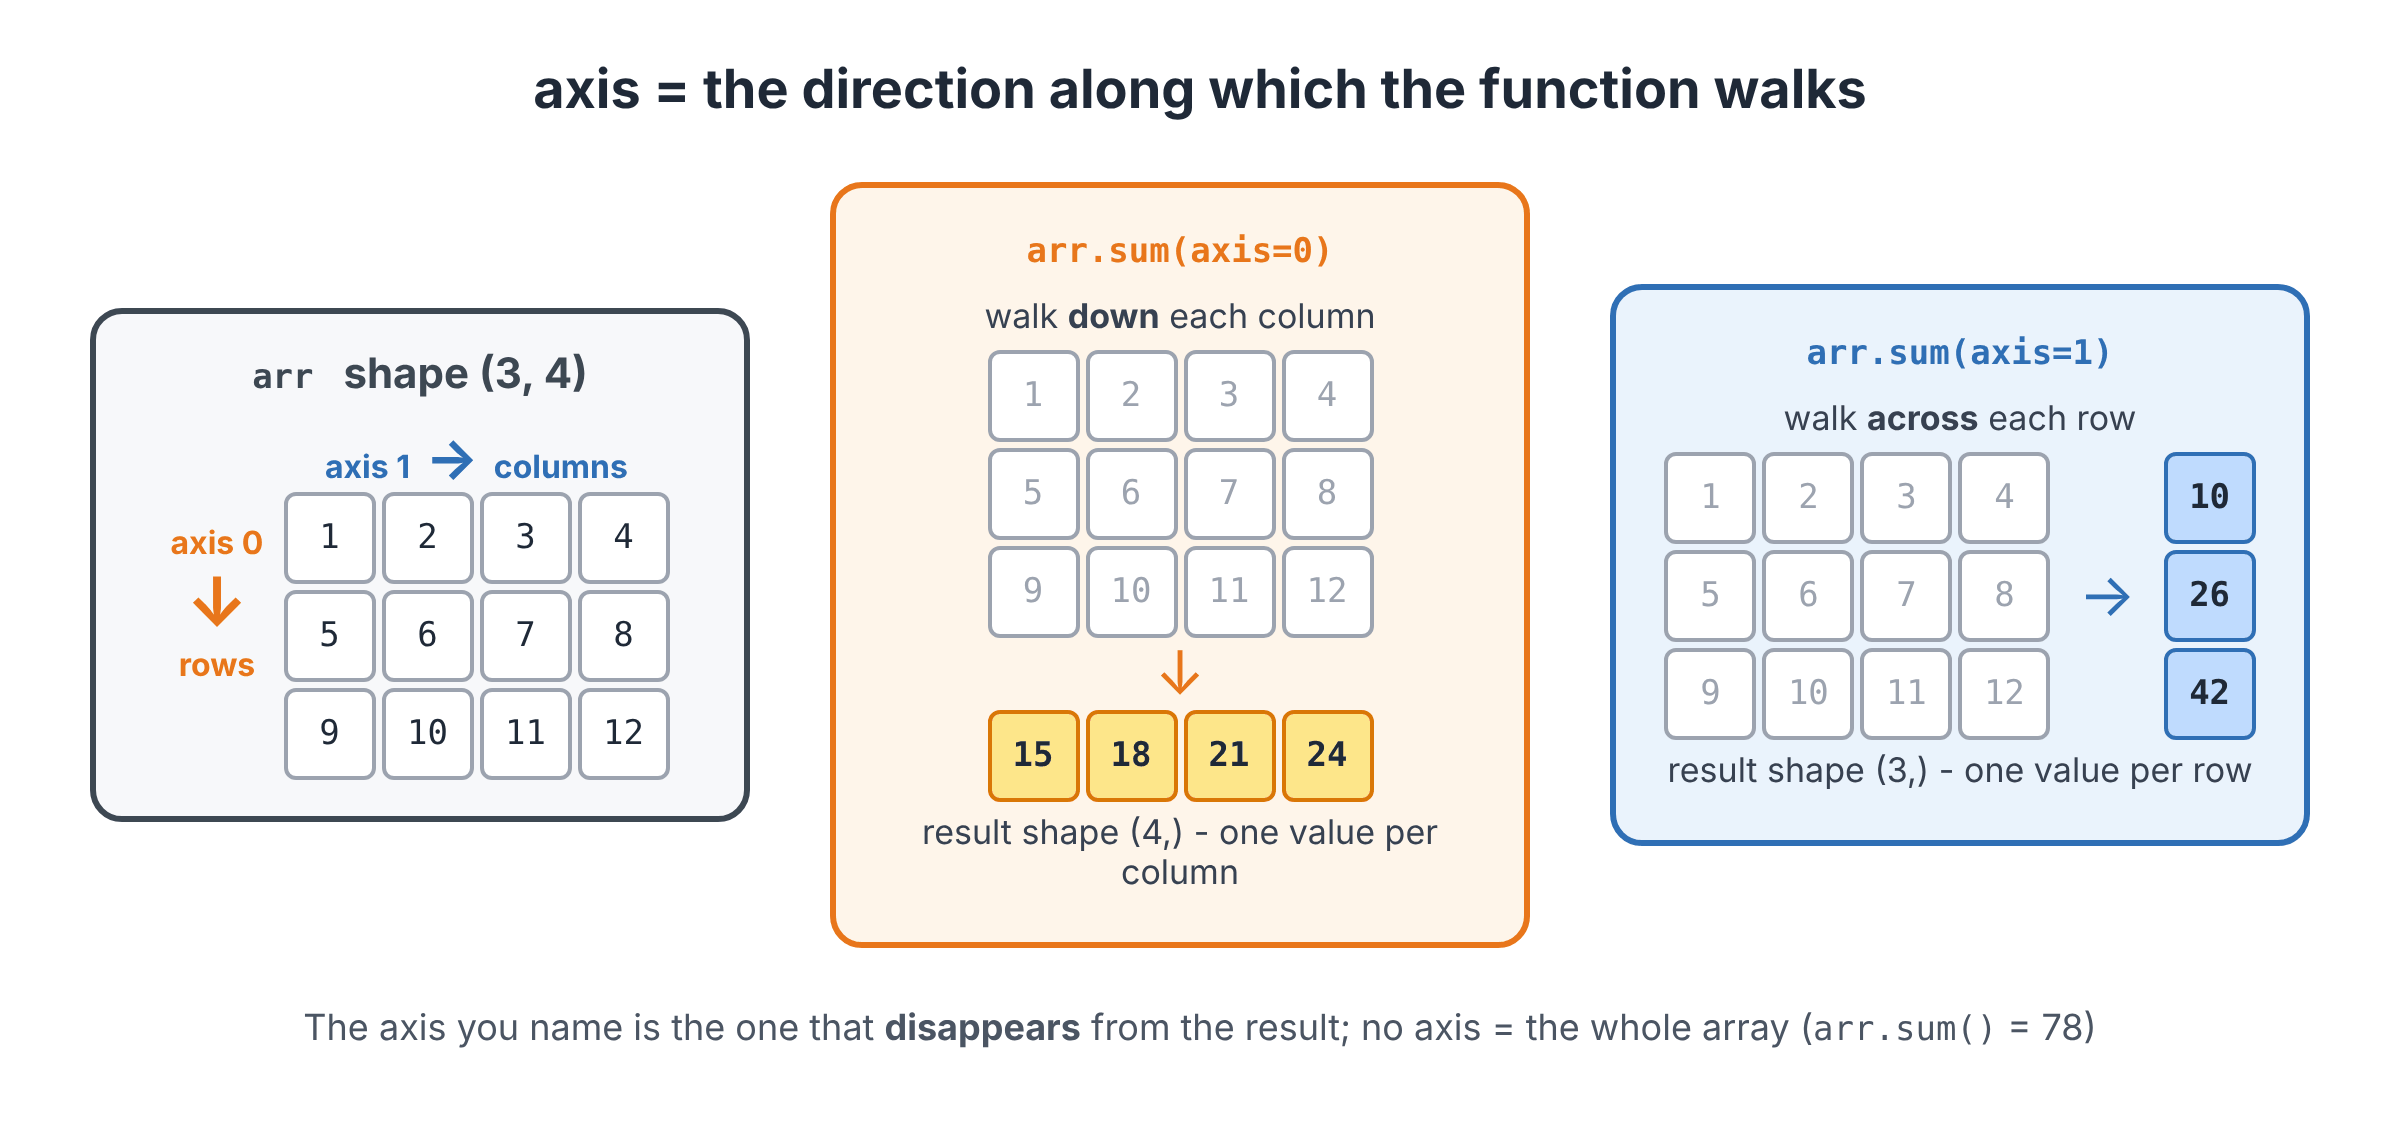

### Basic functions

`axis=0` - down the rows → one value **per column** (per measurement). For iris: mean sepal length, mean sepal width, ...

In [ ]:
iris_data.mean(axis=0)

In [ ]:
iris_data.min(axis=0)

In [ ]:
iris_data.max(axis=0)

In [ ]:
print("whole table :", iris_data.mean())              # no axis -> one number for everything
print("per column  :", iris_data.mean(axis=0))        # shape (4,)
print("per row     :", iris_data.mean(axis=1)[:5])    # shape (150,) - the mean measurement of each flower

### Cumulative functions

`cumsum` - the running total; row 3 of the result is the sum of rows 0-3. Used for "total so far" in time series.

In [ ]:
print(iris_data[0:5])

In [ ]:
print(iris_data.cumsum(axis=0)[0:5])

### YOUR TURN 4: statistics on the iris data

1. Print the mean, median and standard deviation of every column, rounded to 2 decimals.
2. What is the range (max − min) of the petal length?


In [ ]:
# YOUR CODE HERE:

In [ ]:
# 1.
print(iris_data.mean(axis=0).round(2))
print(np.median(iris_data, axis=0).round(2))
print(iris_data.std(axis=0).round(2))

# 2.
print(np.ptp(iris_data[:, 2]))

## Broadcasting

Broadcasting governs how operations work between arrays of different shapes. It can be a powerful feature, but it can cause confusion, even for experienced users.

NumPy stretches the smaller array along the missing dimension - no loop needed
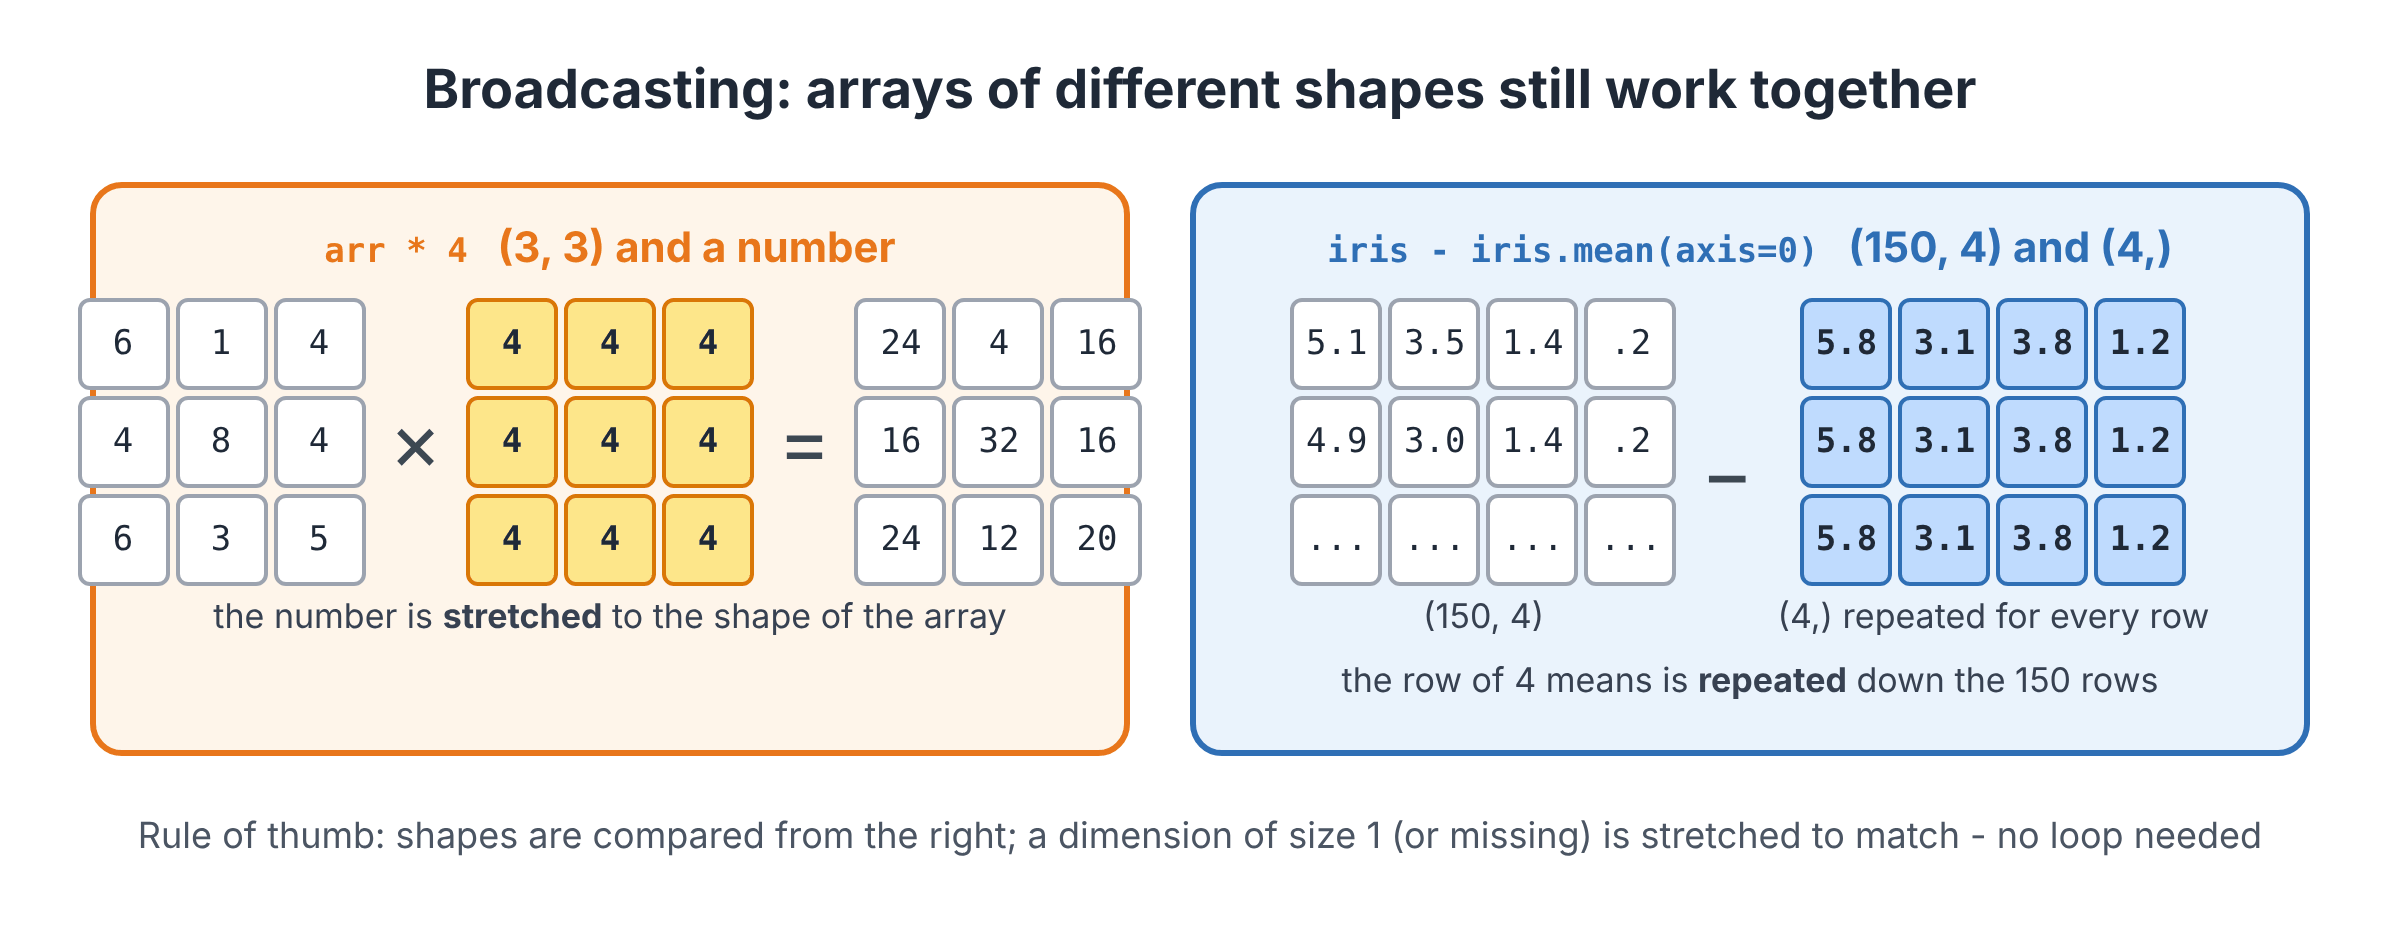

In [ ]:
arr1*4

In [ ]:
(iris_data - iris_data.mean(axis=0))[:10]

What happened in the last cell: `iris_data` has shape `(150, 4)`, the means have shape `(4,)`. NumPy **repeats the row of 4 means for every one of the 150 rows** and subtracts. The result tells, for each flower, how much it differs from the average flower.

The most common use - **standardisation** (z-scores): subtract the mean and divide by the standard deviation, so that every column is on the same scale.

## Saving/Restoring arrays

NumPy has its own binary format (`.npy` - one array, `.npz` - several arrays in one file). It is faster and more exact than CSV and keeps the shape and the dtype.

In [ ]:
np.save("arr1.npy", arr1)
np.load("arr1.npy")

In [ ]:
np.savez("arrs.npz", arr1 = arr1, arr2 = arr2)
loaded = np.load("arrs.npz")
print(loaded["arr1"])
print(loaded["arr2"])

### YOUR TURN 5: a small analysis (if time allows - otherwise at home)

A week of temperatures (°C) in three cities, one row per day, one column per city:

```python
np.random.seed(1)
temps = np.random.randint(-5, 25, size=(7, 3))
```

1. Print the mean temperature of every **city** and of every **day**.
2. On which day (row number) was each city warmest? (`argmax` with the right axis)
3. Was there a day when **all** three cities were above 10 °C? A day when **any** city was below 0 °C?
4. Convert the table to float and replace all negative temperatures with `np.nan`. Then compute the mean per city ignoring the gaps (`np.nanmean`).
5. Convert the whole table to Fahrenheit (`F = C * 9/5 + 32`) - one line, no loop.

In [ ]:
# YOUR CODE HERE:

In [ ]:
np.random.seed(1)
temps = np.random.randint(-5, 25, size=(7, 3))
print(temps)

# 1.
print("per city:", temps.mean(axis=0).round(1))
print("per day :", temps.mean(axis=1).round(1))

# 2.
print(temps.argmax(axis=0))

# 3.
print((temps > 10).all(axis=1).any())      # a day when ALL cities > 10
print((temps < 0).any(axis=1).any())       # a day when ANY city < 0
print(np.where((temps < 0).any(axis=1)))   # which days

# 4.
t = temps.astype(float)
t[t < 0] = np.nan
print(t)
print(np.nanmean(t, axis=0).round(1))

# 5.
print(temps * 9 / 5 + 32)

## Summary

* **ndarray** = one block of equal cells + `shape` + `dtype`; one array - one type (`np.nan` needs float)
* create: `np.zeros`, `np.ones`, `np.arange`, `np.linspace`, `np.random.randint / rand`, `np.array(list)`, `np.genfromtxt(csv)`
* `arr[row, col]`, slices `start:stop:step` per dimension, `::-1` reverses; fancy indexing with a list of positions
* **masks**: `arr[arr > 5]`, combine with `& | ~` in brackets, `.sum()` counts, `.any()` / `.all()`, `np.where`
* a slice is a **view** - use `.copy()` to work on a piece safely
* arithmetic and `np.sqrt`, `np.exp`, ... are **element-wise**; `@` is the matrix product; `np.linalg.solve(A, b)`
* statistics with **`axis`**: `0` = per column (down the rows), `1` = per row; `mean, median, std, var, min, max, ptp, argmax, cumsum`
* **broadcasting** stretches a smaller array (a number, a row of means) to the bigger shape
* `np.save` / `np.load` (`.npy`, `.npz`), `np.savetxt` for CSV


# Thank you